Deliverable 1: G6_2, Tommy Rustad Apelseth, Aron Lerdahl


Task 4: A general function for writing heatwaves to a yml file

In [ ]:
import json
import os
from datetime import date, timedelta

import requests
import yaml

# Reading the client ID from a local file
client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()


# Function to fetch heatwave data from the API
def get_heatwave_data(source_id, start_date, end_date, client_id, sation_name):
    endpoint = "https://frost.met.no/observations/v0.jsonld"
    parameters = {
        "sources": source_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{start_date}/{end_date}",
    }

    date_temp = {}
    loop_start_date = date.fromisoformat(start_date)
    loop_end_date = date.fromisoformat(end_date)
    
    r = requests.get(endpoint, params=parameters, auth=(client_id, ""))
    json_data = r.json()

    if r.status_code != 200:
        print('Error! Returned status code %s' % r.status_code)
        print('Message: %s' % json_data['error']['message'])
        print('Reason: %s' % json_data['error']['reason'])
        return []

    for item in json_data["data"]:
        day = date.fromisoformat(item["referenceTime"][:10])

        for observation in item["observations"]:
            if (
                observation["elementId"] == "max(air_temperature P1D)"
                and observation["timeOffset"] == "PT0H"
                and observation["timeSeriesId"] == 0
            ):
                date_temp[day] = observation["value"]

    heatwaves = []
    hot_days = 0
    heatwave_start = None
    threshold = 27  # Temperature threshold for heatwave

    for day in range((loop_end_date - loop_start_date).days + 1):
        current_date = loop_start_date + timedelta(days=day)
        temperature = date_temp.get(current_date)
        
        if temperature is not None and temperature > threshold:
            if hot_days == 0:
                heatwave_start = current_date
            hot_days += 1
        else:
            if hot_days >= 5:
                heatwaves.append((heatwave_start.isoformat(), (current_date - timedelta(days=1)).isoformat(),))
            hot_days = 0

    output = {
        "dates": [f"{start} - {end}" for start, end in heatwaves],
        "station_id": source_id,
        "station_name": sation_name,
        "year": loop_start_date.year,
    }

    with open("heatwaves.yml", "w", encoding="utf-8") as yaml_file:
        yaml.dump(output, yaml_file, sort_keys=False, allow_unicode=True)

    return output

result = get_heatwave_data("SN17850", "2025-01-01", "2025-12-31", client_id, "Ås")


Deliverable 1: G6_2, Tommy Rustad Apelseth, Aron Lerdahl


Task 5: Graphing the rolling 7-day-average (Re-using Task 1 code, with relevant changes and additions for the rolling average.)

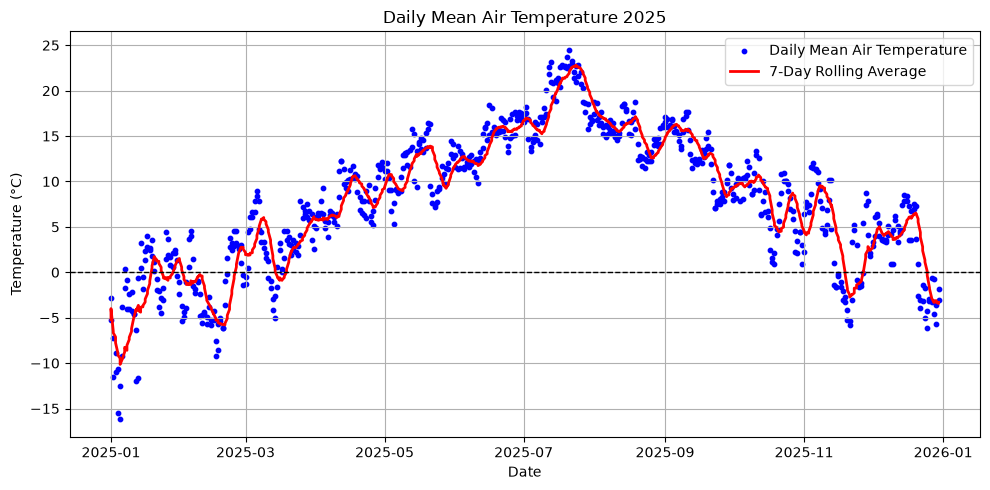

In [58]:
import os

import matplotlib.pyplot as plt
import pandas as pd

# Reading the client ID from a local file
client_path = os.path.expanduser("~/Documents/client.txt")
with open(client_path, encoding="utf-8") as client_file:
    client_id = client_file.read().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

# Issuing a HTTP GET request to the Frost API with the specified parameters and authentication
r = requests.get(endpoint, params=parameters, auth=(client_id, ""))
json_data = r.json()

# Checking if the request was successful
if r.status_code == 200:
    # Extracting the relevant data
    data = json_data["data"]

    # Flattening the data into a list of dictionaries
    rows = []
    for entry in data:
        ref_time = entry["referenceTime"]
        for observation in entry["observations"]:
            rows.append(
                {"datetime": ref_time, "temperature": observation["value"]}
            )

    # Creating a DataFrame
    df = pd.DataFrame(rows)
    df["datetime"] = pd.to_datetime(df["datetime"])

    #Creating a function using pandas to calculate the 7-day rolling average of the temperature
    def calculate_7_day_average(df):
        return df.rolling("7D", on="datetime")["temperature"].mean()

    #Calling the function
    df["7_day_average"] = calculate_7_day_average(df)

    # Using matplotlib to plot the data
    plt.figure(figsize=(10, 5))
    plt.scatter(
        df["datetime"],
        df["temperature"],
        s = 10,
        color="blue",
        label="Daily Mean Air Temperature",
    )
    plt.plot(
        df["datetime"],
        df["7_day_average"],
        color="red",
        linewidth=2,
        label="7-Day Rolling Average",
    )
    plt.axhline(0, color="black", linewidth=1, linestyle="--")

    plt.title("Daily Mean Air Temperature 2025")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.grid()
    plt.legend()
    plt.tight_layout()

    # Displaying the plot
    plt.show()

# If the request was not successful, print the error message
else:
    print(f"Error {r.status_code}: {json_data.get('error', {}).get('message')}")